# 🔍 Castle5000: Image-to-Image Retrieval (Relevance Feedback)

Notebook phục vụ truy vấn ảnh tương đồng dựa trên mô hình lai **SigLIP 2 + DINOv2** kết hợp **Reciprocal Rank Fusion (RRF)**:
- **Tùy chỉnh số lượng top-k**: Dễ dàng điều chỉnh `top_k` cho mỗi lần truy xuất.
- **Hiển thị đầy đủ thông tin**: Mỗi kết quả đều hiển thị `Image ID`, điểm `SigLIP2`, điểm `DINOv2`, và điểm `Hybrid (RRF)`.
- **Hỗ trợ 1 hoặc nhiều ảnh đầu vào**: Nhập 1 hoặc danh sách ID ảnh trực tiếp vào code.
- **Quy trình truy xuất 2 lần (2-Round Retrieval)**:
  - **Lần 1**: Tìm kiếm sơ bộ từ ảnh gốc.
  - **Lần 2**: Thêm các ảnh liên quan tìm được từ lần 1 vào input (Relevance Feedback / Query Expansion) để tinh chỉnh và tìm thêm ảnh liên quan chính xác hơn.
- **Tập trung & Trực quan**: Tập trung vào hiển thị bảng số liệu và lưới ảnh kết quả, không đo độ trễ hay đánh giá hệ thống.

In [4]:
# ==============================================================================
# 1. SETUP MÔI TRƯỜNG & IMPORT THƯ VIỆN
# ==============================================================================
import sys
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

# Thiết lập đường dẫn thư mục gốc
PROJECT_ROOT = Path.cwd()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from src.image2image import (
    ImageToImageRetriever,
    show_query_images,
    show_retrieval_results_with_scores,
    get_image_path,
)

print(f"Project root: {PROJECT_ROOT}")


Project root: d:\MiguelMiguel_DRES_Castle5000


In [5]:
# ==============================================================================
# 2. LOAD METADATA & PRE-COMPUTED EMBEDDINGS
# ==============================================================================
INDEX_DIR = PROJECT_ROOT / "data" / "indexes"

metadata = pd.read_csv(INDEX_DIR / "metadata.csv")
siglip_embeddings = np.load(INDEX_DIR / "siglip_embeddings.npy")
dinov2_embeddings = np.load(INDEX_DIR / "dinov2_embeddings.npy")

print("=== Nạp dữ liệu hoàn tất ===")
print(f"Metadata:         {len(metadata)} ảnh")
print(f"SigLIP2 shape:    {siglip_embeddings.shape}")
print(f"DINOv2 shape:     {dinov2_embeddings.shape}")


=== Nạp dữ liệu hoàn tất ===
Metadata:         5000 ảnh
SigLIP2 shape:    (5000, 768)
DINOv2 shape:     (5000, 384)


In [6]:
# ==============================================================================
# 3. KHỞI TẠO IMAGE RETRIEVER
# ==============================================================================
retriever = ImageToImageRetriever(
    metadata=metadata,
    siglip_embeddings=siglip_embeddings,
    dinov2_embeddings=dinov2_embeddings,
    rrf_k=60,
    default_top_k=20,
    exclude_query_images=True,
)
print("ImageToImageRetriever đã sẵn sàng! ✓")


ImageToImageRetriever đã sẵn sàng! ✓


---
## 🎯 LẦN CHẠY 1: Truy vấn ảnh liên quan từ input ban đầu
- Bạn có thể nhập **1 ảnh** (vd: `["08_527"]`) hoặc **nhiều ảnh** (vd: `["08_527", "08_534"]`).
- Tùy chỉnh tham số `top_k_round1` tùy ý (vd: 10, 15, 20).

[Lần 1] Query IDs input: ['08_527']


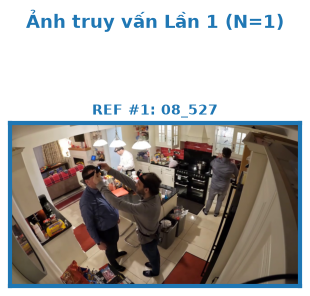


=== BẢNG ĐIỂM CHI TIẾT TRUY VẤN LẦN 1 ===


,Rank,Image ID,SigLIP2 Score,DINOv2 Score,Hybrid Score,File Name
0,1,08_534,0.9547,0.9342,0.032787,08_534.jpg
1,2,08_483,0.9321,0.9109,0.030777,08_483.jpg
2,3,08_541,0.9331,0.8999,0.030536,08_541.jpg
3,4,08_272,0.9355,0.8960,0.030366,08_272.jpg
4,5,08_533,0.9464,0.8934,0.029828,08_533.jpg
5,6,08_269,0.9341,0.8796,0.026378,08_269.jpg
6,7,08_262,0.9176,0.9002,0.024908,08_262.jpg
7,8,08_486,0.9053,0.9178,0.016129,08_486.jpg
8,9,08_509,0.8633,0.9132,0.015873,08_509.jpg
9,10,08_1270,0.9307,0.7678,0.014925,08_1270.jpg


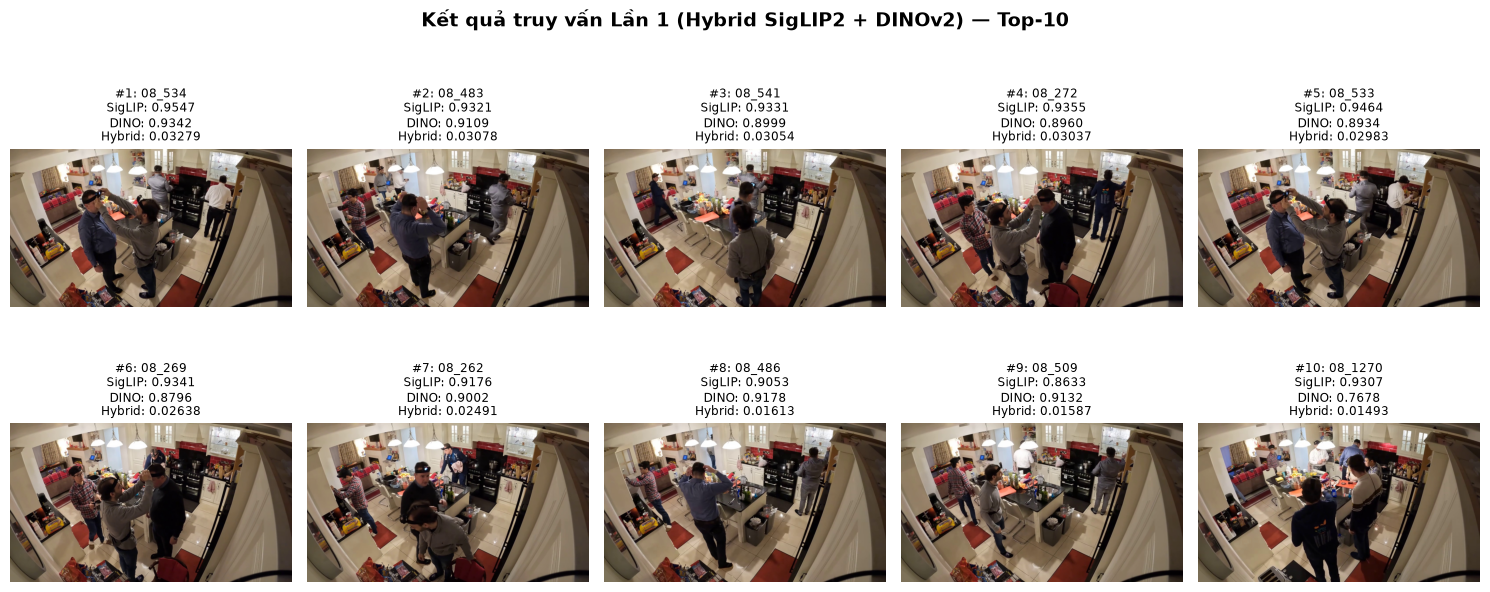

In [7]:
# ==============================================================================
# 🎯 CẤU HÌNH INPUT CHO LẦN 1
# ==============================================================================
# Nhập 1 hoặc nhiều ID ảnh truy vấn ban đầu:
query_ids_round1 = ["08_527"]  # <-- Thay đổi ID tại đây (vd: ["08_527"] hoặc ["08_527", "08_534"])

# Chỉnh số lượng top-k kết quả cần lấy
top_k_round1 = 10

# Chiến lược kết hợp query khi có nhiều ảnh: "mean_embedding" hoặc "per_reference_rrf"
strategy_round1 = "mean_embedding"

# ==============================================================================
# HIỂN THỊ ẢNH TRUY VẤN VÀ THỰC HIỆN TRUY XUẤT LẦN 1
# ==============================================================================
print(f"[Lần 1] Query IDs input: {query_ids_round1}")
show_query_images(metadata, query_ids_round1, title="Ảnh truy vấn Lần 1")

# Chạy truy xuất Lần 1
q1_ids, results_round1, df_round1 = retriever.run_round1(
    query_ids=query_ids_round1,
    top_k=top_k_round1,
    strategy=strategy_round1,
)

# Hiển thị bảng thông tin chi tiết (Rank, Image ID, SigLIP2 Score, DINOv2 Score, Hybrid Score)
print("\n=== BẢNG ĐIỂM CHI TIẾT TRUY VẤN LẦN 1 ===")
display(df_round1)

# Hiển thị trực quan lưới ảnh kết quả kèm điểm số
show_retrieval_results_with_scores(
    results=results_round1,
    title="Kết quả truy vấn Lần 1 (Hybrid SigLIP2 + DINOv2)",
    ncols=5,
)


---
## 🔄 LẦN CHẠY 2: Thêm ảnh liên quan vào input (Relevance Feedback)
- Quan sát các kết quả từ Lần 1 ở trên và chọn thêm các ảnh đúng ngữ cảnh/đối tượng.
- Nhập các ID được chọn vào `selected_relevant_ids` bên dưới.
- Hệ thống sẽ kết hợp ảnh gốc ban đầu + các ảnh liên quan mới chọn để mở rộng query và tìm thêm các ảnh tương đồng tốt hơn.

Ảnh query gốc (Lần 1):          ['08_527']
Ảnh liên quan bổ sung:          ['08_534', '08_533']
Tập ảnh query tổng hợp (Lần 2): ['08_527', '08_534', '08_533']


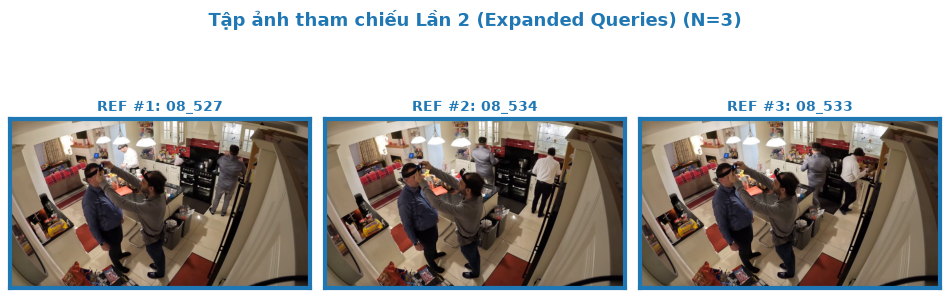


=== BẢNG ĐIỂM CHI TIẾT TRUY VẤN LẦN 2 (SAU RELEVANCE FEEDBACK) ===


,Rank,Image ID,SigLIP2 Score,DINOv2 Score,Hybrid Score,File Name
0,1,08_483,0.9337,0.9102,0.032018,08_483.jpg
1,2,08_272,0.9352,0.8913,0.031514,08_272.jpg
2,3,08_541,0.9265,0.8869,0.027425,08_541.jpg
3,4,08_841,0.9218,0.8926,0.025059,08_841.jpg
4,5,08_994,0.9268,0.8786,0.024563,08_994.jpg
5,6,08_1348,0.9243,0.8809,0.023857,08_1348.jpg
6,7,08_269,0.9229,0.8831,0.023615,08_269.jpg
7,8,08_2190,0.9360,0.6872,0.016393,08_2190.jpg
8,9,08_486,0.9014,0.8999,0.016129,08_486.jpg
9,10,08_915,0.9346,0.8127,0.015873,08_915.jpg


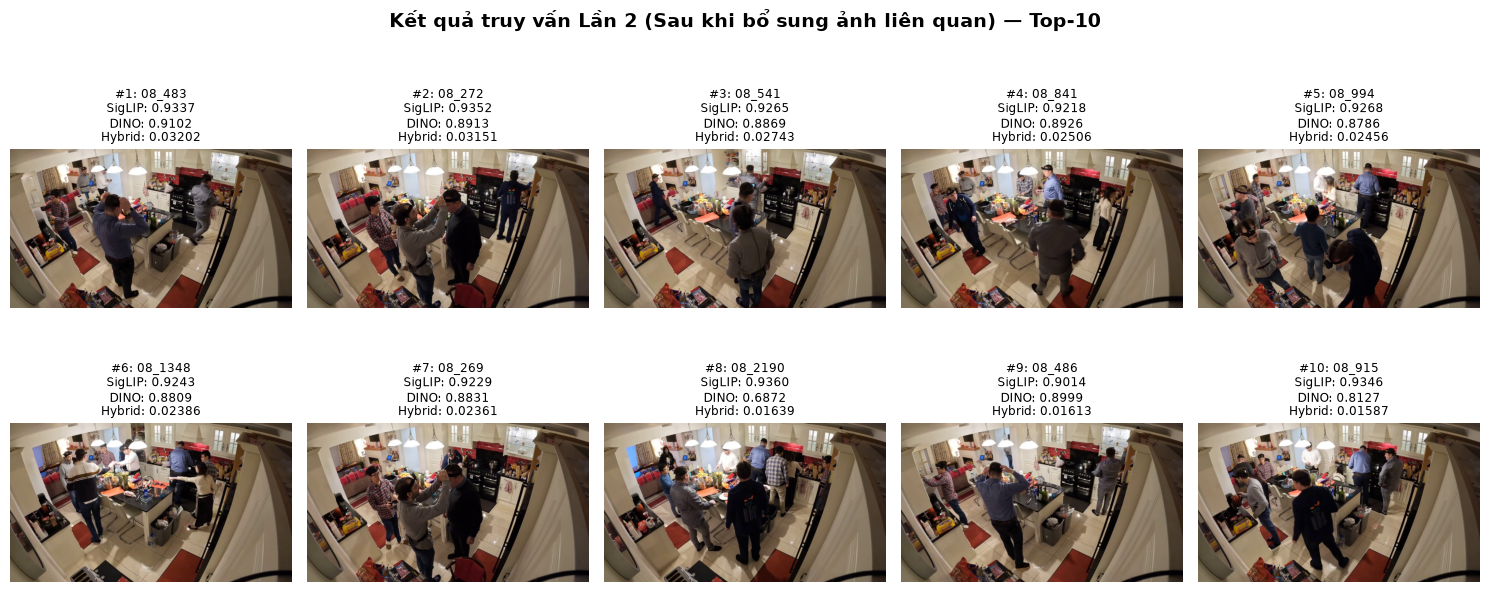

In [8]:
# ==============================================================================
# 🔄 CẤU HÌNH INPUT CHO LẦN 2 (RELEVANCE FEEDBACK)
# ==============================================================================
# Chọn 1 hoặc nhiều ảnh liên quan từ kết quả Lần 1 để bổ sung vào input:
selected_relevant_ids = ["08_534", "08_533"]  # <-- Chọn từ kết quả Lần 1

# Tùy chỉnh số lượng top-k kết quả cho Lần 2
top_k_round2 = 10

# Chiến lược kết hợp nhiều ảnh: "mean_embedding" hoặc "per_reference_rrf"
strategy_round2 = "mean_embedding"

# ==============================================================================
# THỰC HIỆN TRUY VẤN LẦN 2
# ==============================================================================
combined_q_ids, results_round2, df_round2 = retriever.run_round2(
    round1_query_ids=q1_ids,
    additional_relevant_ids=selected_relevant_ids,
    top_k=top_k_round2,
    strategy=strategy_round2,
)

print(f"Ảnh query gốc (Lần 1):          {q1_ids}")
print(f"Ảnh liên quan bổ sung:          {selected_relevant_ids}")
print(f"Tập ảnh query tổng hợp (Lần 2): {combined_q_ids}")

# Hiển thị tất cả ảnh tham chiếu trong tập query mới
show_query_images(metadata, combined_q_ids, title="Tập ảnh tham chiếu Lần 2 (Expanded Queries)")

# Hiển thị bảng thông tin chi tiết Lần 2
print("\n=== BẢNG ĐIỂM CHI TIẾT TRUY VẤN LẦN 2 (SAU RELEVANCE FEEDBACK) ===")
display(df_round2)

# Hiển thị trực quan lưới ảnh kết quả Lần 2 kèm điểm số
show_retrieval_results_with_scores(
    results=results_round2,
    title="Kết quả truy vấn Lần 2 (Sau khi bổ sung ảnh liên quan)",
    ncols=5,
)
